# Proyecto I – Selección de modelos

**Objetivo:** comparar varios modelos de clasificación para predecir `cotiza_pension` y elegir el mejor de forma honesta.

**Reglas de la comparación:**
- Todos los modelos usan los mismos datos, el mismo split y las mismas métricas. Los datos y el split salen del paquete (`cotiza_pension.data`).
- **Entrenamiento (enero–septiembre):** se compara y se ajusta con **validación temporal por meses**, con 3 cortes: entrenar con 1–6 y validar con 7, con 1–7 y validar con 8, y con 1–8 y validar con 9.
- **Prueba (octubre–diciembre):** **no se usa para elegir.** Se evalúa una sola vez, al final, con el modelo ganador. Si se eligiera mirando la prueba, su métrica dejaría de ser honesta.
- **Métricas:**
  - ROC AUC: qué tan bien ordena a quienes cotizan por encima de quienes no.
  - PR-AUC.
  - Brier score: qué tan buenas son las probabilidades; menor es mejor.
- Cada modelo se prueba con y sin `tiene_contrato` (EDA, sección 8.4).

In [7]:
# Librerías
import numpy as np         
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Modelado
from sklearn.model_selection import cross_validate
# .py

from cotiza_pension.data import cargar, separar_temporal, separar_X_y
from cotiza_pension.config import FEATURE_CONTRATO, FEATURES_CAT, FEATURES_NUM

In [8]:
df = cargar()                                   
entrenamiento, prueba = separar_temporal(df)    

X_train, y_train = separar_X_y(entrenamiento)  
X_test,  y_test  = separar_X_y(prueba)         

# Variante sin tiene_contrato
X_train_sc, _ = separar_X_y(entrenamiento, usar_contrato=False)

print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

X_train: (261988, 16)
y_train: (261988,)
X_test: (89733, 16)
y_test: (89733,)


In [9]:
meses = entrenamiento["mes"].to_numpy()
cortes = [
    (np.where(meses <= m)[0], np.where(meses == m + 1)[0]) 
    for m in (6, 7, 8)
]

cortes

[(array([     0,      1,      2, ..., 173084, 173085, 173086],
        shape=(173087,)),
  array([173087, 173088, 173089, ..., 202734, 202735, 202736],
        shape=(29650,))),
 (array([     0,      1,      2, ..., 202734, 202735, 202736],
        shape=(202737,)),
  array([202737, 202738, 202739, ..., 232332, 232333, 232334],
        shape=(29598,))),
 (array([     0,      1,      2, ..., 232332, 232333, 232334],
        shape=(232335,)),
  array([232335, 232336, 232337, ..., 261985, 261986, 261987],
        shape=(29653,)))]

# Armando PIPELINE

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

from cotiza_pension.config import FEATURE_CONTRATO, FEATURES_CAT, FEATURES_NUM


def a_texto(X):
    """Convierte las categóricas a texto; los nulos quedan como la categoría 'nan'."""
    return X.astype(str)


def construir_preprocesador_lineal(columnas):
    """Modelos lineales: imputa y escala las numéricas, one-hot en las categóricas."""
    numerico = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
    categorico = make_pipeline(
        FunctionTransformer(a_texto),
        OneHotEncoder(handle_unknown="ignore", min_frequency=100),
    )
    transformadores = [("num", numerico, FEATURES_NUM), ("cat", categorico, FEATURES_CAT)]
    if FEATURE_CONTRATO in columnas:
        transformadores.append(("contrato", "passthrough", [FEATURE_CONTRATO]))
    return ColumnTransformer(transformadores)


def construir_preprocesador_arboles(columnas):
    """Árboles: no necesitan escalar ni one-hot. Las numéricas pasan tal cual
    (los árboles aceptan nulos) y cada categoría se convierte en un número entero."""
    categorico = make_pipeline(
        FunctionTransformer(a_texto),
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    )
    transformadores = [("num", "passthrough", FEATURES_NUM), ("cat", categorico, FEATURES_CAT)]
    if FEATURE_CONTRATO in columnas:
        transformadores.append(("contrato", "passthrough", [FEATURE_CONTRATO]))
    return ColumnTransformer(transformadores)


## Modelado

**Catálogo de modelos.** Cada modelo usa uno de los dos preprocesadores:
- **Lineal:** escala las numéricas y aplica one-hot a las categóricas. Lo usan Dummy y las logísticas.
- **Árboles:** deja las numéricas sin escalar y convierte las categorías en números enteros. Lo usan el árbol, Random Forest, HistGradientBoosting y XGBoost.

Se descartan SVM y KNN: con unas 260 mil filas son muy lentos de entrenar y predecir, y en datos tabulares no suelen superar al boosting.

In [11]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

SEMILLA = 42
# Posición de las categóricas en la salida del preprocesador de árboles (van después de las numéricas)
cat_idx = list(range(len(FEATURES_NUM), len(FEATURES_NUM) + len(FEATURES_CAT)))

catalogo = {
    # nombre: (tipo de preprocesador, modelo)
    "dummy": ("lineal", DummyClassifier(strategy="prior")),  # línea base: siempre predice la tasa promedio
    "logistica_l2": ("lineal", LogisticRegression(max_iter=1000)),
    "logistica_l1": ("lineal", LogisticRegression(solver="liblinear", l1_ratio=1, C=0.5)),  # l1_ratio=1 -> L1
    "arbol": ("arboles", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEMILLA)),
    "random_forest": ("arboles", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEMILLA)),
    "hist_boosting": ("arboles", HistGradientBoostingClassifier(
        categorical_features=cat_idx, random_state=SEMILLA)),
    "xgboost": ("arboles", XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6, tree_method="hist",
        enable_categorical=True, max_cat_to_onehot=1, n_jobs=-1, random_state=SEMILLA)),
}


def construir_pipeline_notebook(nombre, columnas):
    """Arma preprocesador + modelo según el tipo que indica el catálogo."""
    tipo, modelo = catalogo[nombre]
    modelo = clone(modelo)  # copia limpia, para no modificar el modelo del catálogo
    if tipo == "lineal":
        pre = construir_preprocesador_lineal(columnas)
    else:
        pre = construir_preprocesador_arboles(columnas)
    if nombre == "xgboost":
        # Le dice a XGBoost qué columnas son categóricas ("c") y cuáles numéricas ("q").
        # El orden es el de la salida del preprocesador: numéricas, categóricas, contrato.
        tipos = ["q"] * len(FEATURES_NUM) + ["c"] * len(FEATURES_CAT)
        if FEATURE_CONTRATO in columnas:
            tipos.append("q")
        modelo.set_params(feature_types=tipos)
    return Pipeline([("preprocesador", pre), ("clasificador", modelo)])

In [12]:
import time
from sklearn.model_selection import cross_validate

metricas = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}
variantes = {"con contrato": X_train, "sin contrato": X_train_sc}

filas = []
for nombre in catalogo:
    for variante, X in variantes.items():
        inicio = time.time()
        res = cross_validate(construir_pipeline_notebook(nombre, X.columns), X, y_train,
                             cv=cortes, scoring=metricas)
        filas.append({
            "modelo": nombre,
            "variante": variante,
            "roc_auc": res["test_roc_auc"].mean(),
            "roc_auc_std": res["test_roc_auc"].std(),
            "pr_auc": res["test_pr_auc"].mean(),
            "brier": -res["test_brier"].mean(),   # se invierte el signo: menor es mejor
            "segundos": time.time() - inicio,
        })
        print(f"{nombre:15s} {variante:13s} AUC={filas[-1]['roc_auc']:.4f}")

resultados = pd.DataFrame(filas).sort_values("roc_auc", ascending=False)
resultados.round(4)


dummy           con contrato  AUC=0.5000
dummy           sin contrato  AUC=0.5000
logistica_l2    con contrato  AUC=0.9690
logistica_l2    sin contrato  AUC=0.9690
logistica_l1    con contrato  AUC=0.9690
logistica_l1    sin contrato  AUC=0.9690
arbol           con contrato  AUC=0.9717
arbol           sin contrato  AUC=0.9709
random_forest   con contrato  AUC=0.9788
random_forest   sin contrato  AUC=0.9780
hist_boosting   con contrato  AUC=0.9822
hist_boosting   sin contrato  AUC=0.9821
xgboost         con contrato  AUC=0.9824
xgboost         sin contrato  AUC=0.9822


,modelo,variante,roc_auc,roc_auc_std,pr_auc,brier,segundos
12,xgboost,con contrato,0.9824,0.0003,0.9793,0.0485,18.6058
13,xgboost,sin contrato,0.9822,0.0002,0.9792,0.0487,14.3241
10,hist_boosting,con contrato,0.9822,0.0003,0.9792,0.0487,14.8582
11,hist_boosting,sin contrato,0.9821,0.0003,0.9792,0.0488,15.8579
8,random_forest,con contrato,0.9788,0.0002,0.9753,0.0544,30.6093
9,random_forest,sin contrato,0.9780,0.0001,0.9744,0.0559,28.6545
6,arbol,con contrato,0.9717,0.0006,0.9637,0.0608,4.3379
7,arbol,sin contrato,0.9709,0.0006,0.9629,0.0617,4.3274
5,logistica_l1,sin contrato,0.9690,0.0008,0.9618,0.0647,34.5644
4,logistica_l1,con contrato,0.9690,0.0008,0.9618,0.0647,33.0060


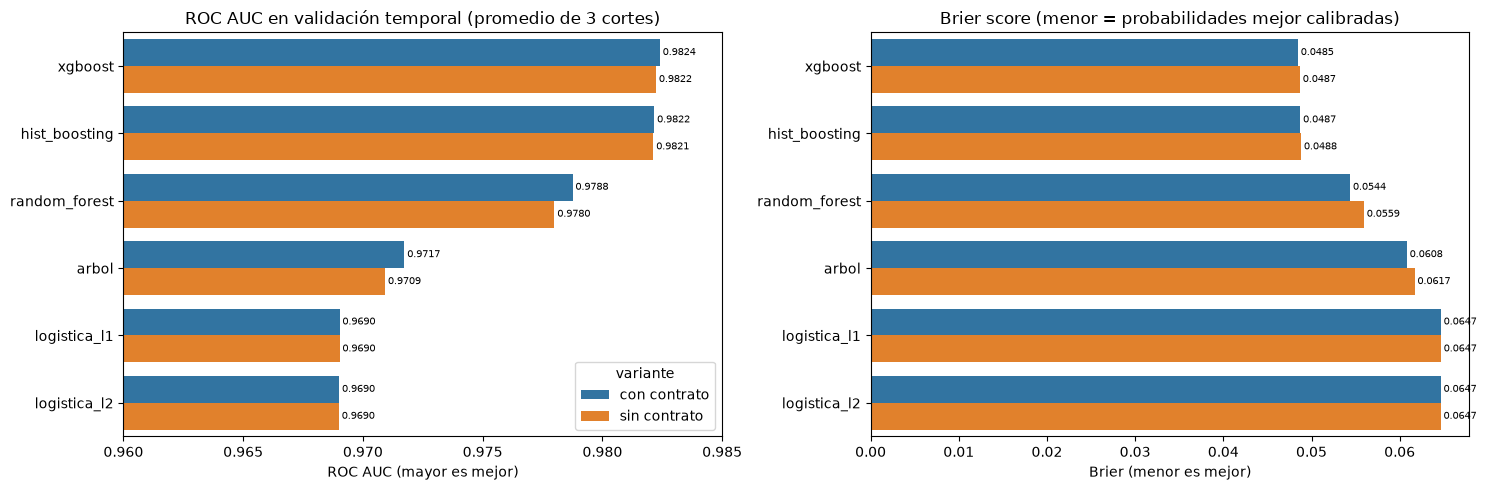

In [13]:
sin_dummy = resultados[resultados["modelo"] != "dummy"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=sin_dummy, x="roc_auc", y="modelo", hue="variante", ax=axes[0])
axes[0].set_xlim(0.96, 0.985)
axes[0].set_title("ROC AUC en validación temporal (promedio de 3 cortes)")
axes[0].set_xlabel("ROC AUC (mayor es mejor)")
sns.barplot(data=sin_dummy, x="brier", y="modelo", hue="variante", ax=axes[1], legend=False)
axes[1].set_title("Brier score (menor = probabilidades mejor calibradas)")
axes[1].set_xlabel("Brier (menor es mejor)")
for ax in axes:
    ax.set_ylabel("")
    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.4f", fontsize=7, padding=2)
plt.tight_layout()
plt.show()

**Lectura de la comparación:**

| Modelo | AUC con contrato | AUC sin contrato | Brier |
|---|---|---|---|
| XGBoost | 0,9824 | 0,9822 | 0,0485 |
| HistGradientBoosting | 0,9822 | 0,9821 | 0,0487 |
| Random Forest | 0,9788 | 0,9780 | 0,0544 |
| Árbol de decisión | 0,9717 | 0,9709 | 0,0608 |
| Logística L2 y L1 | 0,9690 | 0,9690 | 0,0647 |
| Dummy (línea base) | 0,5000 | 0,5000 | 0,2457 |

1. **Todos los modelos superan con amplitud la línea base** (AUC de 0,50).
2. **Los dos boosting son los mejores** y están empatados en la práctica. La diferencia entre ellos (0,0002) es menor que la variación entre cortes (unos 0,0003). Le sacan unos 0,3 puntos de AUC a Random Forest y 1,3 a la logística.
3. **Los resultados son estables:** la desviación entre los 3 cortes es de 0,0008 o menos en todos los modelos, así que las diferencias no son ruido.
4. **`tiene_contrato` no aporta nada en ningún modelo** (diferencias de 0,0008 o menos). Confirma lo visto en el EDA: la variable repite la posición ocupacional. **Se quita del modelo**, y la app pide un dato menos.
5. **L1 da lo mismo que L2 y tarda unas 4 veces más.** La logística sigue siendo útil como modelo interpretable, a 1,3 puntos del mejor.
6. **¿Es sospechoso un AUC de 0,98?** Se midió el AUC de cada variable por separado. La más fuerte (tamaño de empresa) llega a 0,92 y la segunda (ingreso) también a 0,92; ninguna se acerca a 1. El 0,98 sale de combinar variables que ya separan mucho cada una, no de una variable que filtre la respuesta.

**Pasan al ajuste de hiperparámetros:** XGBoost y HistGradientBoosting, sin `tiene_contrato`.

## Ajuste de hiperparámetros

Búsqueda aleatoria (`RandomizedSearchCV`) con **20 combinaciones** por modelo, cada una evaluada con los **mismos 3 cortes por mes**. Se elige por ROC AUC y también se guarda el Brier. Todo se hace con los datos de entrenamiento (enero–septiembre): la prueba sigue sin tocarse.

⏱️ Tarda unos 9 minutos.

In [ ]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

# Rangos a explorar para los dos finalistas (sin tiene_contrato: no aporta)
espacios = {
    "hist_boosting": {
        "clasificador__learning_rate": loguniform(0.02, 0.3),
        "clasificador__max_iter": randint(200, 1000),
        "clasificador__max_leaf_nodes": [15, 31, 63, 127],
        "clasificador__min_samples_leaf": [20, 50, 100, 200],
        "clasificador__l2_regularization": loguniform(1e-3, 10),
    },
    "xgboost": {
        "clasificador__n_estimators": randint(200, 800),
        "clasificador__learning_rate": loguniform(0.02, 0.3),
        "clasificador__max_depth": randint(3, 10),
        "clasificador__min_child_weight": loguniform(1, 50),
        "clasificador__subsample": uniform(0.6, 0.4),         # entre 0,6 y 1,0
        "clasificador__colsample_bytree": uniform(0.6, 0.4),  # entre 0,6 y 1,0
        "clasificador__reg_lambda": loguniform(0.1, 10),
    },
}

busquedas = {}
for nombre, espacio in espacios.items():
    inicio = time.time()
    busqueda = RandomizedSearchCV(
        construir_pipeline_notebook(nombre, X_train_sc.columns),
        espacio,
        n_iter=20,                 # 20 combinaciones al azar
        cv=cortes,                 # los mismos cortes por mes
        scoring={"roc_auc": "roc_auc", "brier": "neg_brier_score"},
        refit="roc_auc",           # elige por AUC
        random_state=SEMILLA,
    )
    busqueda.fit(X_train_sc, y_train)
    busquedas[nombre] = busqueda
    print(f"{nombre}: AUC={busqueda.best_score_:.4f} ({(time.time() - inicio) / 60:.1f} min)")

# Tabla comparativa: mejor combinación de cada modelo frente a su versión por defecto
por_defecto = resultados[resultados["variante"] == "sin contrato"].set_index("modelo")
resumen = pd.DataFrame([
    {
        "modelo": nombre,
        "roc_auc_por_defecto": por_defecto.loc[nombre, "roc_auc"],
        "roc_auc_ajustado": b.best_score_,
        "roc_auc_std": b.cv_results_["std_test_roc_auc"][b.best_index_],
        "brier_por_defecto": por_defecto.loc[nombre, "brier"],
        "brier_ajustado": -b.cv_results_["mean_test_brier"][b.best_index_],
    }
    for nombre, b in busquedas.items()
]).sort_values("roc_auc_ajustado", ascending=False)
resumen.round(4)

In [ ]:
# Mejores hiperparámetros encontrados
for nombre, b in busquedas.items():
    print(nombre)
    for parametro, valor in b.best_params_.items():
        print(f"   {parametro.replace('clasificador__', '')}: {valor:.4g}")

**Resultado del ajuste (sin `tiene_contrato`):**

| Modelo | AUC por defecto | AUC ajustado | Brier por defecto | Brier ajustado |
|---|---|---|---|---|
| **XGBoost** | 0,9822 | **0,9829** | 0,0487 | **0,0477** |
| HistGradientBoosting | 0,9821 | 0,9826 | 0,0488 | 0,0483 |

El ajuste mejora poco a los dos modelos (entre 0,0005 y 0,0007 de AUC): los valores por defecto ya eran buenos. Las combinaciones ganadoras usan una tasa de aprendizaje baja (unos 0,02–0,03) con muchos árboles (unos 670–750), que es el patrón habitual del boosting.

## Decisión

**Modelo elegido: XGBoost ajustado, sin `tiene_contrato`.**
- Es el mejor en las dos métricas de la validación temporal: AUC de 0,9829 y Brier de 0,0477.
- La ventaja sobre HistGradientBoosting es mínima (0,0003 de AUC, más o menos una desviación entre cortes). Por eso **HistGradientBoosting queda como alternativa equivalente**: es más simple y no necesita una librería extra.
- `tiene_contrato` sale del modelo porque no cambia el desempeño en ninguno de los 7 modelos y repite la posición ocupacional.

Las secciones siguientes revisan el modelo elegido: calibración e importancia de variables (todavía en validación) y, al final, la evaluación única en prueba.

## Revisión del modelo elegido

### Calibración

El modelo entrega una **probabilidad**, y la app la va a mostrar. Por eso no basta con que ordene bien (AUC): también debe estar **calibrado**. Por ejemplo, de las personas a las que les asigna 70 %, cerca del 70 % debería cotizar de verdad.

Se usan las predicciones fuera de muestra de los 3 cortes: julio, agosto y septiembre, cada mes predicho con un modelo entrenado solo con los meses anteriores. La prueba todavía no se toca.

⏱️ Tarda menos de 1 minuto.

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

ganador = "xgboost"
params_ganador = busquedas[ganador].best_params_

# Predicciones fuera de muestra: en cada corte se entrena con los meses anteriores
# y se predice el mes de validación (7, 8 y 9). Nada de esto usa la prueba.
proba_val = np.full(len(X_train_sc), np.nan)
for idx_fit, idx_val in cortes:
    modelo_corte = construir_pipeline_notebook(ganador, X_train_sc.columns)
    modelo_corte.set_params(**params_ganador)
    modelo_corte.fit(X_train_sc.iloc[idx_fit], y_train.iloc[idx_fit])
    proba_val[idx_val] = modelo_corte.predict_proba(X_train_sc.iloc[idx_val])[:, 1]

modelo_septiembre = modelo_corte  # el del último corte: entrenado con enero–agosto

en_validacion = ~np.isnan(proba_val)
y_val = y_train.to_numpy()[en_validacion]
p_val = proba_val[en_validacion]
print(f"Validación (julio–septiembre, {en_validacion.sum():,} personas)")
print(f"  AUC:   {roc_auc_score(y_val, p_val):.4f}")
print(f"  Brier: {brier_score_loss(y_val, p_val):.4f}")

# Curva de calibración: en cada tramo de probabilidad predicha, ¿qué % cotiza de verdad?
frac_real, prob_media = calibration_curve(y_val, p_val, n_bins=10, strategy="uniform")
tramos = pd.cut(p_val, bins=np.linspace(0, 1, 11), include_lowest=True)
tabla_calibracion = pd.DataFrame({"y": y_val, "p": p_val, "tramo": tramos}).groupby(
    "tramo", observed=True
).agg(personas=("y", "size"), prob_predicha=("p", "mean"), cotiza_real=("y", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
axes[0].plot(prob_media, frac_real, marker="o", label="XGBoost ajustado")
axes[0].set_xlabel("Probabilidad predicha de cotizar")
axes[0].set_ylabel("Proporción que cotiza de verdad")
axes[0].set_title("Curva de calibración (validación julio–septiembre)")
axes[0].legend()

axes[1].hist(p_val[y_val == 0], bins=40, alpha=0.6, color="tab:red", label="No cotiza")
axes[1].hist(p_val[y_val == 1], bins=40, alpha=0.6, color="tab:green", label="Cotiza")
axes[1].set_xlabel("Probabilidad predicha de cotizar")
axes[1].set_ylabel("Número de personas")
axes[1].set_title("Distribución de las probabilidades predichas")
axes[1].legend()
plt.tight_layout()
plt.show()

tabla_calibracion.round(3)

**El modelo está bien calibrado.** En todos los tramos, la probabilidad predicha y la proporción real difieren en 2,4 puntos o menos. Por ejemplo, entre las personas a las que les asigna de 70 % a 80 % (75,1 % en promedio), cotiza de verdad el 72,8 %. En los tramos intermedios (0,2–0,5 y 0,7–0,8) el modelo **sobreestima un poco** la probabilidad de cotizar, unos 2 puntos. No hace falta recalibrarlo.

El histograma muestra que el modelo está **muy seguro en la mayoría de los casos**:
- El 80 % de las personas recibe una probabilidad menor a 0,1 o mayor a 0,9 (40.986 + 30.602 de 88.901).
- En esos extremos casi siempre acierta: cotiza de verdad el 1,8 % de los que reciben menos de 0,1 y el 98,4 % de los que reciben más de 0,9.
- Los casos dudosos, entre 0,3 y 0,7, son solo el 7 %.

### Importancia de variables

**Importancia por permutación:** se toma el modelo del último corte (entrenado con enero–agosto) y se mide en septiembre. Para cada variable se desordenan sus valores y se mira cuánto cae el AUC: si cae mucho, el modelo depende de esa variable.

Frente a la importancia interna de XGBoost tiene dos ventajas:
- Se mide en datos que el modelo no vio.
- Se mide sobre las variables originales, no sobre las columnas codificadas.

In [ ]:
from matplotlib.container import BarContainer
from sklearn.inspection import permutation_importance

# Se usa el modelo del último corte (entrenado con enero–agosto) y se mide en septiembre.
# Para cada variable se desordenan sus valores y se mira cuánto cae el AUC:
# si cae mucho, el modelo depende de esa variable.
idx_septiembre = cortes[-1][1]
X_sep = X_train_sc.iloc[idx_septiembre]
y_sep = y_train.iloc[idx_septiembre]
permutacion = permutation_importance(
    modelo_septiembre, X_sep, y_sep, scoring="roc_auc", n_repeats=5, random_state=SEMILLA
)

importancias = pd.DataFrame({
    "variable": X_sep.columns,
    "caida_auc": permutacion.importances_mean,
    "std": permutacion.importances_std,
}).sort_values("caida_auc")

ax = importancias.plot(kind="barh", x="variable", y="caida_auc", xerr="std", legend=False,
                       figsize=(9, 6))
for barras in ax.containers:
    if isinstance(barras, BarContainer):
        ax.bar_label(barras, fmt="%.4f", fontsize=8, padding=3)
ax.set_xlabel("Caída del AUC al desordenar la variable (mayor = más importante)")
ax.set_ylabel("")
ax.set_title("Importancia por permutación (XGBoost, validación de septiembre)")
plt.tight_layout()
plt.show()

importancias.sort_values("caida_auc", ascending=False).round(4)

**Dos variables explican casi todo:** el tamaño de empresa (el AUC cae 0,059 si se desordena) y el ingreso en SMMLV (cae 0,037). Les siguen, muy lejos, la rama de actividad (0,008), la posición ocupacional, el nivel educativo, el departamento y la edad (entre 0,003 y 0,005).

- **Posición y educación:** separaban mucho en el EDA, pero aquí tienen poca importancia propia. Buena parte de lo que dicen ya está en el tamaño de empresa y el ingreso, con los que están relacionadas (EDA, sección 8.6).
- **Zona, parentesco, sexo y estado civil casi no aportan** (0,0002 o menos). Se podrían quitar para simplificar la app. La zona, además, ya queda cubierta por el departamento y la rama.
- **Es consistente con el AUC de cada variable por separado** (tamaño de empresa 0,92, ingreso 0,92): el modelo se apoya en lo que ya se veía en los datos, no en una variable extraña.

## Evaluación final en prueba (octubre–diciembre)

⚠️ **Esta sección se corre una sola vez**, con el modelo ya elegido. Después de ver el resultado no se cambia nada del modelo: si se ajustara mirando la prueba, su métrica dejaría de ser honesta.

El modelo final es el que entregó la búsqueda: XGBoost con los mejores hiperparámetros, reentrenado con todo enero–septiembre, sin `tiene_contrato`.

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_auc_score,
)

# ⚠️ Esta celda se corre UNA sola vez, con el modelo ya elegido.
X_test_sc, y_test = separar_X_y(prueba, usar_contrato=False)
final = busquedas[ganador].best_estimator_  # ya reentrenado con todo enero–septiembre
p_test = final.predict_proba(X_test_sc)[:, 1]
pred_test = (p_test >= 0.5).astype(int)

comparacion = pd.DataFrame({
    "validación (jul–sep)": {
        "roc_auc": roc_auc_score(y_val, p_val),
        "pr_auc": average_precision_score(y_val, p_val),
        "brier": brier_score_loss(y_val, p_val),
    },
    "prueba (oct–dic)": {
        "roc_auc": roc_auc_score(y_test, p_test),
        "pr_auc": average_precision_score(y_test, p_test),
        "brier": brier_score_loss(y_test, p_test),
    },
})
print(comparacion.round(4), end="\n\n")

print("AUC en prueba por mes:")
for mes in sorted(prueba["mes"].unique()):
    es_mes = (prueba["mes"] == mes).to_numpy()
    print(f"  mes {mes}: {roc_auc_score(y_test[es_mes], p_test[es_mes]):.4f}")
print()

print(classification_report(y_test, pred_test, target_names=["No cotiza", "Cotiza"], digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["No cotiza", "Cotiza"], values_format=",d", cmap="Blues"
)
plt.title("Matriz de confusión en prueba (umbral 0,5)")
plt.show()

**El desempeño se mantiene en datos nuevos:**

| Métrica | Validación (jul–sep) | Prueba (oct–dic) |
|---|---|---|
| ROC AUC | 0,9829 | 0,9819 |
| PR-AUC | 0,9800 | 0,9787 |
| Brier | 0,0477 | 0,0490 |

- **El AUC solo cae 0,001** y es casi igual en octubre (0,9823), noviembre (0,9817) y diciembre (0,9819). No hay señales de sobreajuste ni de deterioro con el tiempo.
- **Con el umbral de 0,5, el modelo acierta en el 93,4 % de los casos:**
  - De quienes no cotizan detecta el 94,8 % (recall), y cuando dice "no cotiza" acierta el 93,8 % (precisión).
  - De quienes cotizan detecta el 91,5 %.
- **El umbral de 0,5 es una elección por defecto.** Si el uso fuera encontrar no cotizantes, por ejemplo para una campaña de afiliación, se podría subir: el modelo marcaría como "no cotiza" a más personas, y detectaría más casos a cambio de más falsas alarmas.

### Grupo de interés: ganan 1 SMMLV o más

Es el grupo donde el modelo sería más útil (EDA, sección 8.5): tienen ingreso para cotizar y una parte no lo hace.

In [ ]:
from sklearn.metrics import recall_score

# Grupo de interés: ganan 1 SMMLV o más (tienen ingreso para cotizar)
grupo = (prueba["gana_1_smmlv_o_mas"] == 1).to_numpy()
y_g, p_g, pred_g = y_test.to_numpy()[grupo], p_test[grupo], pred_test[grupo]

print(f"Personas en prueba que ganan 1 SMMLV o más: {grupo.sum():,}")
print(f"  No cotizan de verdad:            {(y_g == 0).sum():,} ({(y_g == 0).mean():.1%})")
print(f"  El modelo predice que no cotizan: {(pred_g == 0).sum():,}")
print(f"  AUC dentro del grupo:            {roc_auc_score(y_g, p_g):.4f}")
print(f"  Brier dentro del grupo:          {brier_score_loss(y_g, p_g):.4f}")
print(f"  % de no cotizantes detectados:   {recall_score(y_g, pred_g, pos_label=0):.1%}")
print()

# Mismas métricas por posición ocupacional dentro del grupo
detalle = pd.DataFrame({
    "posicion": prueba.loc[grupo, "posicion_ocupacional"].to_numpy(),
    "no_cotiza": y_g == 0,
    "predice_no_cotiza": pred_g == 0,
})
detalle["detectado"] = detalle["no_cotiza"] & detalle["predice_no_cotiza"]
por_posicion = detalle.groupby("posicion").agg(
    personas=("no_cotiza", "size"),
    no_cotiza_real=("no_cotiza", "mean"),
    no_cotiza_predicho=("predice_no_cotiza", "mean"),
    no_cotizantes=("no_cotiza", "sum"),
    detectados=("detectado", "sum"),
)
por_posicion["% detectados"] = por_posicion["detectados"] / por_posicion["no_cotizantes"].where(
    por_posicion["no_cotizantes"] > 0
)
por_posicion.sort_values("personas", ascending=False).round(3)

**Resultados en el grupo:**
- En prueba hay **48.186 personas** que ganan 1 SMMLV o más, y el **27,3 %** de ellas (13.169) no cotiza.
- **Dentro del grupo el AUC baja a 0,964** (frente a 0,982 en general) y el Brier sube a 0,066. Es esperable: aquí el ingreso, la segunda variable más importante, separa menos, porque todos ganan lo suficiente.
- **El modelo detecta al 82,6 % de los no cotizantes del grupo.**
- **El punto débil son los empleados de empresa particular.** El modelo solo encuentra al 66,7 % de sus no cotizantes, que en prueba son 4.480 personas. Son asalariados con ingreso suficiente que no cotizan, y su perfil se parece al de quienes sí lo hacen. En cambio, entre los cuenta propia detecta al 92,6 %.
- En los empleados del gobierno de este grupo no hay ningún no cotizante, por eso su porcentaje queda vacío.

Esta diferencia es una **limitación del modelo** y debe quedar en el README.

## Conclusiones de la selección de modelos

1. **Comparación:** se compararon 7 modelos con validación temporal por meses. Los dos boosting fueron los mejores, y **XGBoost ajustado** quedó primero por un margen mínimo sobre HistGradientBoosting.
2. **`tiene_contrato` sale del modelo**, porque no mejora ninguno de los 7.
3. **Revisión del ganador:** está bien calibrado y se apoya sobre todo en el tamaño de empresa y el ingreso.
4. **Prueba (octubre–diciembre):** logra un AUC de 0,982 y un 93,4 % de acierto, casi igual que en validación.
5. **Limitaciones:**
   - Desempeño menor en el grupo que gana 1 SMMLV o más (AUC de 0,964), sobre todo con los asalariados de empresa particular.
   - El modelo se entrena sin el factor de expansión, así que describe la muestra de la encuesta y no la población ponderada.
   - El cambio de la jornada legal (Ley 2101) puede alterar el significado de `horas_semana` en 2026.

**Qué sigue (en `src/`):**
- `features.py`: los dos preprocesadores de este notebook.
- `model.py`: el catálogo y `construir_pipeline(nombre)`.
- `config.py`: `MODELO_FINAL = "xgboost"`, sus hiperparámetros y la decisión de no usar `tiene_contrato`.
- `train.py`: entrenar con enero–septiembre, evaluar en octubre–diciembre y guardar el modelo en `models/`.
- Después, este notebook debe **importar** esas funciones desde `src/` en lugar de definirlas.